<a href="https://colab.research.google.com/github/kvikaee/data-analysis-python/blob/main/4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Кошурина Виктория Евгеньевна

412977

PYАД 1.5

# Задание 4. Разведочный анализ данных (Exploratory Data Analysis, EDA) с использованием matplotlib
### Цель задания
Провести самостоятельный разведочный анализ реального набора данных, содержащего категориальные признаки, с применением только библиотеки matplotlib для визуализации.
Цель — научиться быстро анализировать структуру данных, находить пропуски, аномалии и делать обоснованные выводы на основе графиков и статистик.


Датасет: [imdb-рейтинг (топ-1000) ](https://disk.yandex.ru/d/9xHKBELeT1pBSA):

Взяла этот датасет, потому что здесь есть много данных, а также пропуски, с которыми можно поработать.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tabulate import tabulate

In [ ]:
imdb = 'imdb_top_1000.csv'
df = pd.read_csv(imdb)

In [ ]:
print(tabulate(
    df.head(5),
    headers='keys',
    tablefmt='simple_grid',
    showindex=False,
    maxcolwidths=20
))

┌──────────────────────┬─────────────────────┬─────────────────┬───────────────┬───────────┬──────────────────────┬───────────────┬──────────────────────┬──────────────┬──────────────────────┬────────────────┬────────────────┬───────────────┬────────────────┬───────────────┬─────────────┐
│ Poster_Link          │ Series_Title        │   Released_Year │ Certificate   │ Runtime   │ Genre                │   IMDB_Rating │ Overview             │   Meta_score │ Director             │ Star1          │ Star2          │ Star3         │ Star4          │   No_of_Votes │ Gross       │
├──────────────────────┼─────────────────────┼─────────────────┼───────────────┼───────────┼──────────────────────┼───────────────┼──────────────────────┼──────────────┼──────────────────────┼────────────────┼────────────────┼───────────────┼────────────────┼───────────────┼─────────────┤
│ https://m.media-amaz │ The Shawshank       │            1994 │ A             │ 142 min   │ Drama                │           9.3 

# 1.	Общая характеристика данных (мин)


*   Количество строк и столбцов.
*   Типы признаков (числовые, категориальные).

*   Описание целевой переменной (если есть) или ключевых признаков.


In [ ]:
num_rows = len(df)  # количество строк
num_columns = len(df.columns)  # количество признаков

# Описание признаков в датасете
columns_description = {
    "Тип данных": df.dtypes,
    "Шкала": [
        "Категориальная" if df[col].dtype == 'object' else
        "Числовая" if df[col].dtype in ['int64', 'float64'] else "Неопределено"
        for col in df.columns
    ]
}

description_df = pd.DataFrame(columns_description)

# Выводим информацию о количестве строк и признаков
print(f"Количество строк: {num_rows}")
print(f"Количество признаков: {num_columns}")

# Строим таблицу с описанием признаков
description_df


Количество строк: 1000
Количество признаков: 16


,Тип данных,Шкала
Poster_Link,object,Категориальная
Series_Title,object,Категориальная
Released_Year,object,Категориальная
Certificate,object,Категориальная
Runtime,object,Категориальная
Genre,object,Категориальная
IMDB_Rating,float64,Числовая
Overview,object,Категориальная
Meta_score,float64,Числовая
Director,object,Категориальная


# 2.	Анализ пропусков
* Выявление пропущенных значений (включая скрытые, например, "?", "N/A", пустые строки).
*  Анализ пропусков, в т.ч. и с помощью matplotlib.


In [ ]:
print("ЯВНЫЕ ПРОПУСКИ:")
print(df.isna().sum())

print("\n" + "="*50 + "\n")

# Скрытые пропуски для строковых столбцов
print("СКРЫТЫЕ ПРОПУСКИ:")
for col in df.select_dtypes(include=['object']).columns:
  empty = (df[col].astype(str).str.strip() == '').sum()
    # N/A-подобные значения
  na = df[col].isin(['N/A', 'NA', '?', 'nan']).sum()

  hidden = empty + na

  if hidden > 0:
    print(f"{col}: {hidden}")
  else:
    print(f"{col}: Скрытые пропуски не найдены")


ЯВНЫЕ ПРОПУСКИ:
Poster_Link        0
Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64


СКРЫТЫЕ ПРОПУСКИ:
Poster_Link: Скрытые пропуски не найдены
Series_Title: Скрытые пропуски не найдены
Released_Year: Скрытые пропуски не найдены
Certificate: Скрытые пропуски не найдены
Runtime: Скрытые пропуски не найдены
Genre: Скрытые пропуски не найдены
Overview: Скрытые пропуски не найдены
Director: Скрытые пропуски не найдены
Star1: Скрытые пропуски не найдены
Star2: Скрытые пропуски не найдены
Star3: Скрытые пропуски не найдены
Star4: Скрытые пропуски не найдены
Gross: Скрытые пропуски не найдены


# 3.	Статистические оценки
* Для числовых признаков: среднее, медиана, стандартное отклонение, минимум/максимум.
* Для категориальных признаков: частоты (мода, распределение категорий).
* Представление этих оценок в виде таблицы или графиков (например, гистограммы, bar plots).


Нам надо заполнить пропуски в Meta_score, в Certificate и в Gross

Я решила посчитать корреляция между imdb-рейтингом и метакритику, для того, чтобы определить стратегию заполнения пропусков. Если корреляция большая, то можно взять среднее соседей, если маленькая - лучше взять медиану, так как большой разброс.

In [ ]:
df_temp = df.dropna(subset=['Meta_score'])
print(df_temp[['IMDB_Rating', 'Meta_score']].corr())


             IMDB_Rating  Meta_score
IMDB_Rating     1.000000    0.268531
Meta_score      0.268531    1.000000


In [ ]:
# Сохраняем индексы пропусков ДО заполнения
missing_indices = df[df['Meta_score'].isna()].index.tolist()

print(f"Пропусков найдено: {len(missing_indices)}")
# print(f"Индексы: {missing_indices}\n")

# Заполняем Meta_score медианой
median_value = df['Meta_score'].median()
df['Meta_score'] = df['Meta_score'].fillna(median_value)

# Выводим фильмы, где был пропуск
if len(missing_indices) > 0:
    # result = df.loc[missing_indices, ['Series_Title', 'IMDB_Rating', 'Meta_score']]

    # print(tabulate(
    #     result,
    #     headers='keys',
    #     tablefmt='simple_grid',
    #     showindex=False
    # ))

    print(f"\nВсего заполнено: {len(missing_indices)}")
    print(f"Meta_score медиана: {median_value}")
else:
    print("Пропусков не найдено")


Пропусков найдено: 157

Всего заполнено: 157
Meta_score медиана: 79.0


Заполнение Certificate

Если жанр не подбирается, то оставляем ему PG-13 как самое дефолтное значение.

In [ ]:
missing_cert_indices = df[df['Certificate'].isna()].index.tolist()

print(f"Пропусков найдено: {len(missing_cert_indices)}")

# Для каждого жанра найти самый частый рейтинг
genre_cert_mode = df.dropna(subset=['Certificate']).groupby('Genre')['Certificate'].agg(
    lambda x: x.mode()[0] if len(x.mode()) > 0 else 'PG-13'
)

# Заполняем пропуски
count = 0
for idx in missing_cert_indices:
    genre = df.loc[idx, 'Genre']
    title = df.loc[idx, 'Series_Title']

    new_cert = genre_cert_mode.get(genre, 'PG-13')
    df.loc[idx, 'Certificate'] = new_cert

    if count < 5:
        print(f"  {title} ({genre}) → {new_cert}")

    count += 1

if count > 5:
    print(f"  ... и ещё {count - 5} фильмов")

print(f"\nВсего заполнено: {len(missing_cert_indices)}")
print(f"Пропусков осталось: {df['Certificate'].isna().sum()}")

Пропусков найдено: 101
  Seppuku (Action, Drama, Mystery) → A
  Ayla: The Daughter of War (Biography, Drama, History) → R
  Tengoku to jigoku (Crime, Drama, Mystery) → R
  Babam ve Oglum (Drama, Family) → U
  Ikiru (Drama) → R
  ... и ещё 96 фильмов

Всего заполнено: 101
Пропусков осталось: 0


Заполним Gross, так как разброс большой

In [ ]:
# Сначала очищаем Gross от $, запятых и пробелов
df['Gross'] = df['Gross'].astype(str).str.replace('$', '').str.replace(',', '').str.strip()

# Потом конвертируем в числа
df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')

# Сохраняем индексы пропусков ДО заполнения
missing_indices = df[df['Gross'].isna()].index.tolist()

print(f"Пропусков найдено: {len(missing_indices)}")

# Заполняем Gross медианой
median_value = df['Gross'].median()
df['Gross'] = df['Gross'].fillna(median_value)

# Выводим информацию
if len(missing_indices) > 0:
    print(f"\nВсего заполнено: {len(missing_indices)}")
    print(f"Gross медиана: ${median_value:,.0f}")
else:
    print("Пропусков не найдено")

print(f"\nNaN в Gross после заполнения: {df['Gross'].isna().sum()}")


Пропусков найдено: 169

Всего заполнено: 169
Gross медиана: $23,530,892

NaN в Gross после заполнения: 0


Сравнение изначальной и заполненной таблиц

In [ ]:
df_original = pd.read_csv('imdb_top_1000.csv')
df_full = df

In [ ]:
print(tabulate(
    df_full.tail(3),
    headers='keys',
    tablefmt='simple_grid',
    showindex=False,
    maxcolwidths=20
))

print(tabulate(
    df_original.tail(3),
    headers='keys',
    tablefmt='simple_grid',
    showindex=False,
    maxcolwidths=20
))


┌──────────────────────┬────────────────┬─────────────────┬───────────────┬───────────┬─────────────────────┬───────────────┬──────────────────────┬──────────────┬──────────────────┬───────────────────┬───────────────────┬────────────────┬────────────────┬───────────────┬─────────────┐
│ Poster_Link          │ Series_Title   │   Released_Year │ Certificate   │ Runtime   │ Genre               │   IMDB_Rating │ Overview             │   Meta_score │ Director         │ Star1             │ Star2             │ Star3          │ Star4          │   No_of_Votes │       Gross │
├──────────────────────┼────────────────┼─────────────────┼───────────────┼───────────┼─────────────────────┼───────────────┼──────────────────────┼──────────────┼──────────────────┼───────────────────┼───────────────────┼────────────────┼────────────────┼───────────────┼─────────────┤
│ https://m.media-amaz │ From Here to   │            1953 │ Passed        │ 118 min   │ Drama, Romance, War │           7.6 │ In Hawaii in 

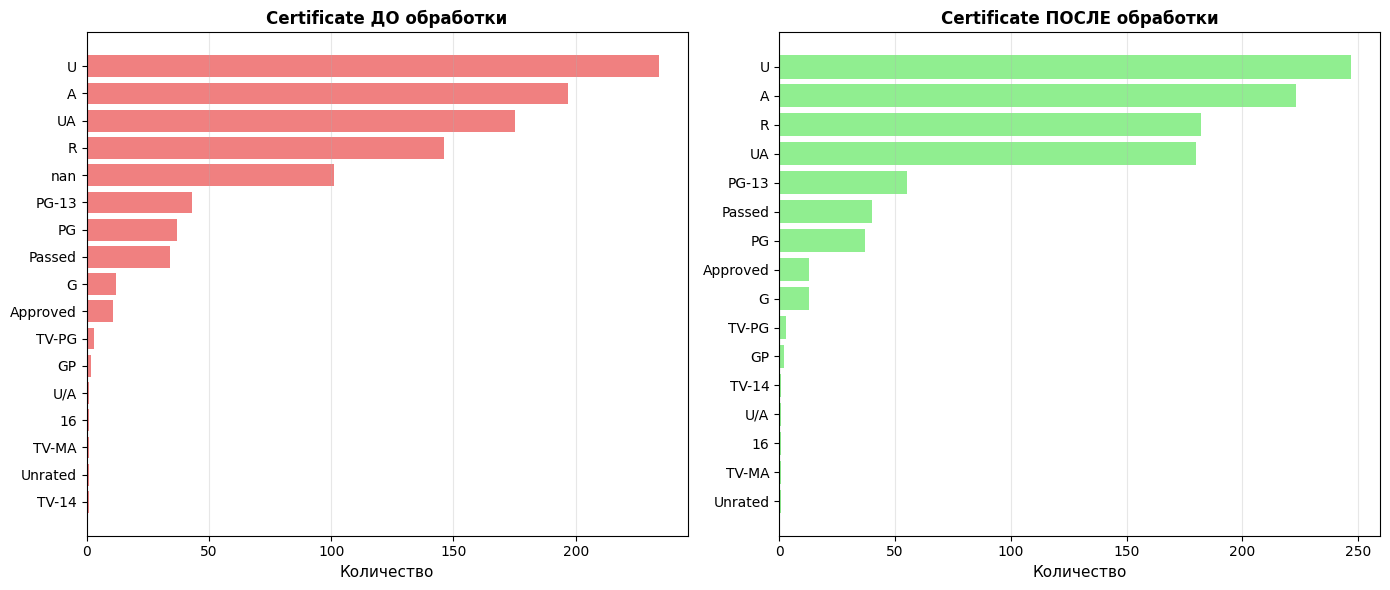

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ДО (df_original)
cert_before = df_original['Certificate'].value_counts(dropna=False).sort_values(ascending=True)
axes[0].barh([str(x) for x in cert_before.index], cert_before.values, color='lightcoral')
axes[0].set_xlabel('Количество', fontsize=11)
axes[0].set_title('Certificate ДО обработки', fontsize=12, fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# ПОСЛЕ (df_full)
cert_after = df_full['Certificate'].value_counts().sort_values(ascending=True)
axes[1].barh([str(x) for x in cert_after.index], cert_after.values, color='lightgreen')
axes[1].set_xlabel('Количество', fontsize=11)
axes[1].set_title('Certificate ПОСЛЕ обработки', fontsize=12, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


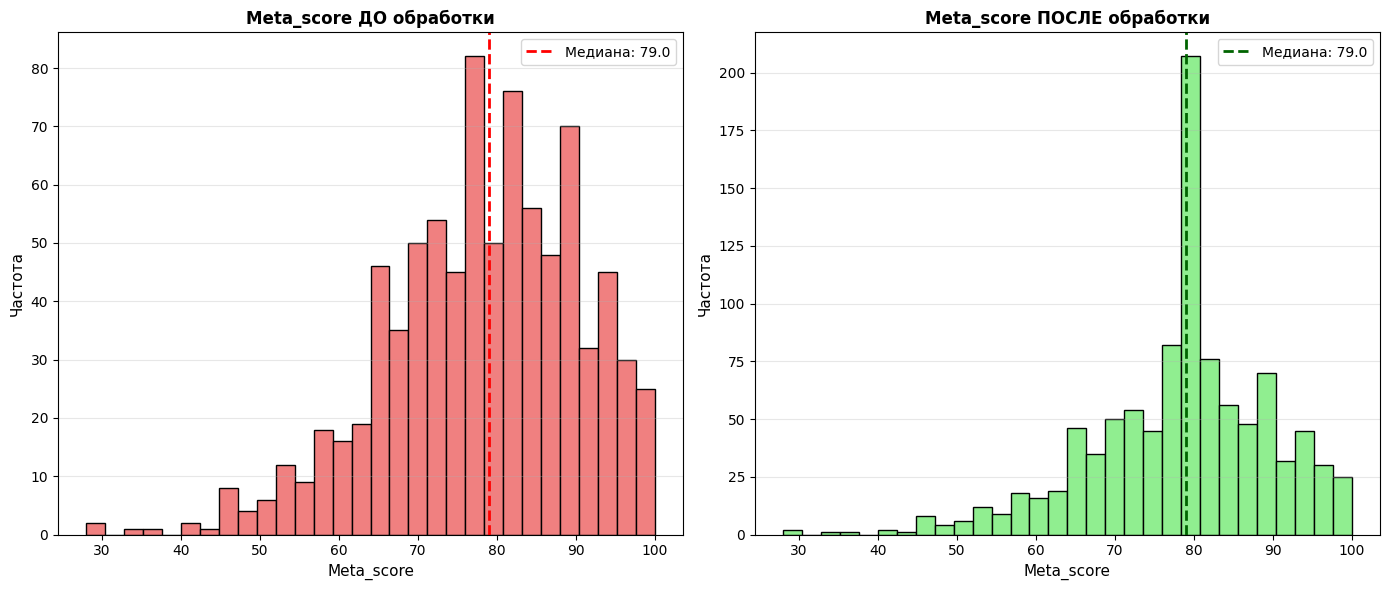

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ДО (df_original) - без пропусков
meta_before = df_original['Meta_score'].dropna()
axes[0].hist(meta_before, bins=30, color='lightcoral', edgecolor='black')
axes[0].set_xlabel('Meta_score', fontsize=11)
axes[0].set_ylabel('Частота', fontsize=11)
axes[0].set_title('Meta_score ДО обработки', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].axvline(meta_before.median(), color='red', linestyle='--', linewidth=2, label=f'Медиана: {meta_before.median()}')
axes[0].legend()

# ПОСЛЕ (df_full) - со всеми значениями
meta_after = df_full['Meta_score']
axes[1].hist(meta_after, bins=30, color='lightgreen', edgecolor='black')
axes[1].set_xlabel('Meta_score', fontsize=11)
axes[1].set_ylabel('Частота', fontsize=11)
axes[1].set_title('Meta_score ПОСЛЕ обработки', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].axvline(meta_after.median(), color='darkgreen', linestyle='--', linewidth=2, label=f'Медиана: {meta_after.median()}')
axes[1].legend()

plt.tight_layout()
plt.show()

# 4.	Выявление аномалий (выбросов)
* Визуальное и/или статистическое обнаружение выбросов в числовых признаках.
* Использование box plots или scatter plots для демонстрации аномалий.


RUNTIME - ВЫЯВЛЕНИЕ АНОМАЛИЙ

Всего значений: 1000


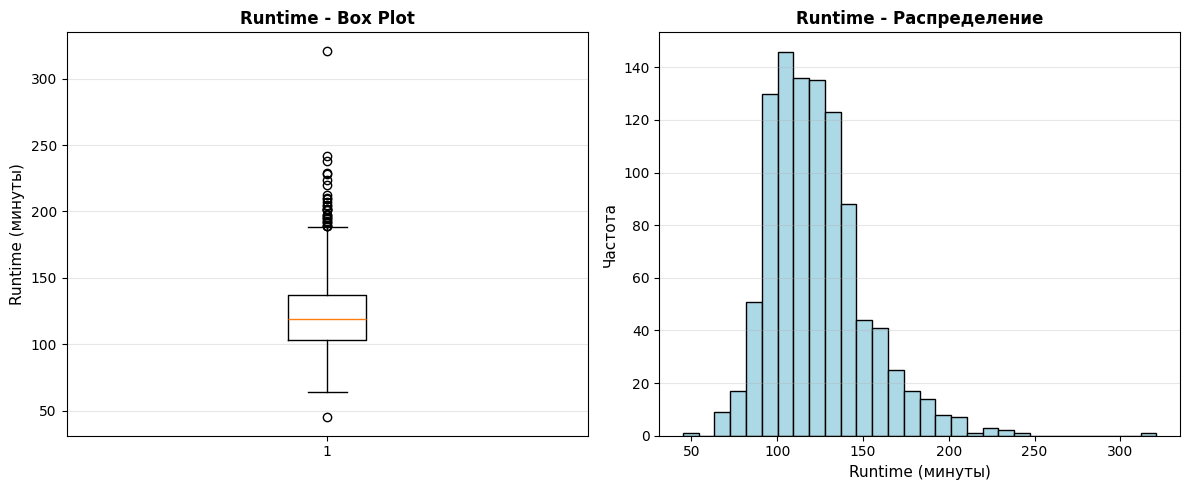


Q1 (25%): 103.00
Q3 (75%): 137.00
IQR: 34.00
Нижний предел: 52.00
Верхний предел: 188.00
Выбросов: 29 (2.9%)
Min: 45.00, Max: 321.00
Среднее: 122.89, Медиана: 119.00


In [ ]:
print("RUNTIME - ВЫЯВЛЕНИЕ АНОМАЛИЙ")


# Сначала нужно очистить Runtime
runtime_clean = df_full['Runtime'].str.replace(' min', '').astype(float)

print(f"\nВсего значений: {runtime_clean.notna().sum()}")

# Box plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(runtime_clean.dropna(), vert=True)
axes[0].set_ylabel('Runtime (минуты)', fontsize=11)
axes[0].set_title('Runtime - Box Plot', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Гистограмма распределения
axes[1].hist(runtime_clean.dropna(), bins=30, color='lightblue', edgecolor='black')
axes[1].set_xlabel('Runtime (минуты)', fontsize=11)
axes[1].set_ylabel('Частота', fontsize=11)
axes[1].set_title('Runtime - Распределение', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Статистика выбросов
Q1 = runtime_clean.quantile(0.25)
Q3 = runtime_clean.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = runtime_clean[(runtime_clean < lower_bound) | (runtime_clean > upper_bound)]

print(f"\nQ1 (25%): {Q1:.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижний предел: {lower_bound:.2f}")
print(f"Верхний предел: {upper_bound:.2f}")
print(f"Выбросов: {len(outliers)} ({len(outliers)/len(df_full)*100:.1f}%)")
print(f"Min: {runtime_clean.min():.2f}, Max: {runtime_clean.max():.2f}")
print(f"Среднее: {runtime_clean.mean():.2f}, Медиана: {runtime_clean.median():.2f}")

IMDB_RATING - ВЫЯВЛЕНИЕ АНОМАЛИЙ

Всего значений: 1000


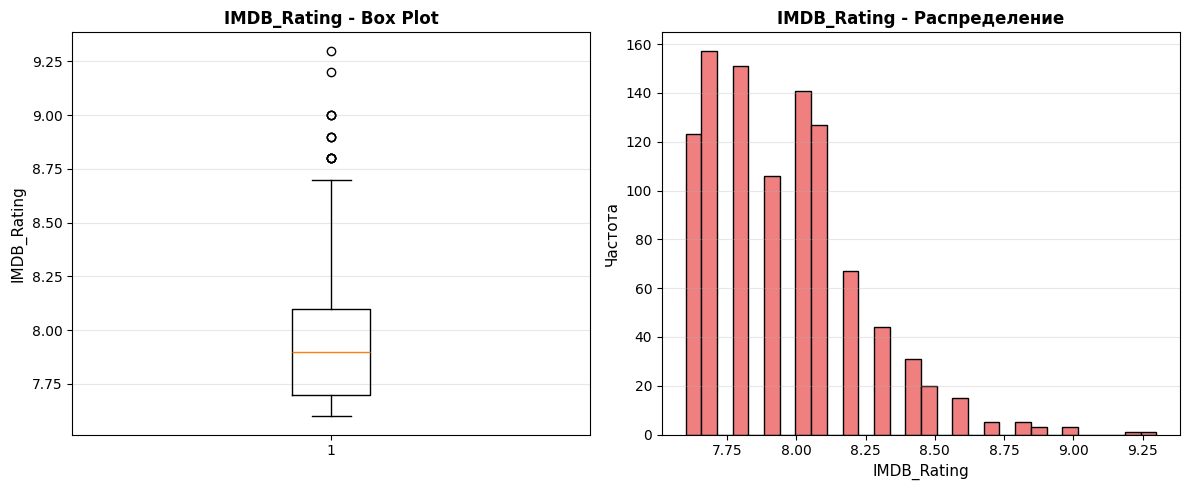


Q1 (25%): 7.70
Q3 (75%): 8.10
IQR: 0.40
Нижний предел: 7.10
Верхний предел: 8.70
Выбросов: 13 (1.3%)
Min: 7.60, Max: 9.30
Среднее: 7.95, Медиана: 7.90


In [ ]:
print("IMDB_RATING - ВЫЯВЛЕНИЕ АНОМАЛИЙ")

print(f"\nВсего значений: {df_full['IMDB_Rating'].notna().sum()}")

# Box plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df_full['IMDB_Rating'].dropna(), vert=True)
axes[0].set_ylabel('IMDB_Rating', fontsize=11)
axes[0].set_title('IMDB_Rating - Box Plot', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Гистограмма распределения
axes[1].hist(df_full['IMDB_Rating'].dropna(), bins=30, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('IMDB_Rating', fontsize=11)
axes[1].set_ylabel('Частота', fontsize=11)
axes[1].set_title('IMDB_Rating - Распределение', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Статистика выбросов
Q1 = df_full['IMDB_Rating'].quantile(0.25)
Q3 = df_full['IMDB_Rating'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_full[(df_full['IMDB_Rating'] < lower_bound) | (df_full['IMDB_Rating'] > upper_bound)]['IMDB_Rating']

print(f"\nQ1 (25%): {Q1:.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижний предел: {lower_bound:.2f}")
print(f"Верхний предел: {upper_bound:.2f}")
print(f"Выбросов: {len(outliers)} ({len(outliers)/len(df_full)*100:.1f}%)")
print(f"Min: {df_full['IMDB_Rating'].min():.2f}, Max: {df_full['IMDB_Rating'].max():.2f}")
print(f"Среднее: {df_full['IMDB_Rating'].mean():.2f}, Медиана: {df_full['IMDB_Rating'].median():.2f}")


META_SCORE - ВЫЯВЛЕНИЕ АНОМАЛИЙ

Всего значений: 1000


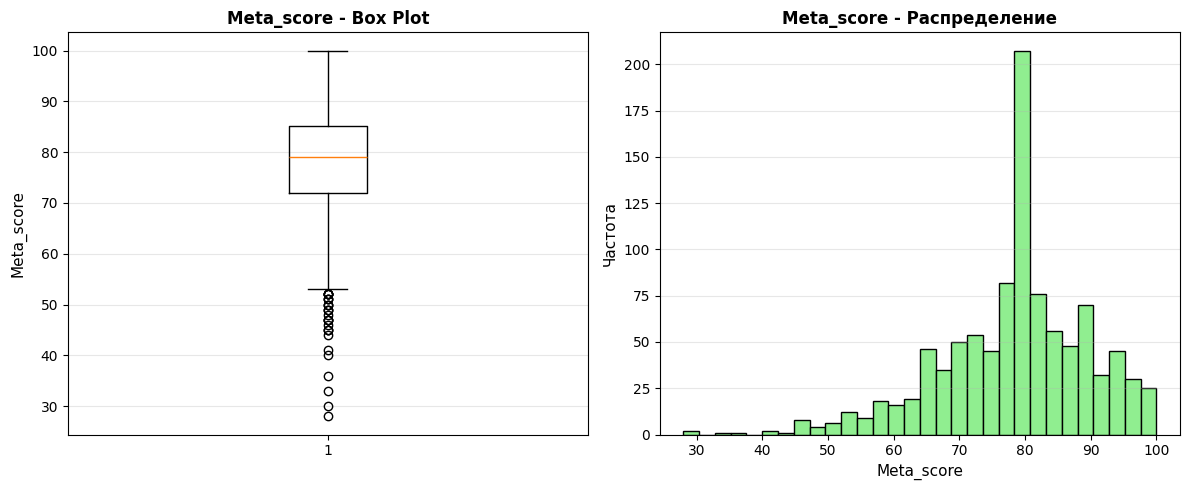


Q1 (25%): 72.00
Q3 (75%): 85.25
IQR: 13.25
Нижний предел: 52.12
Верхний предел: 105.12
Выбросов: 31 (3.1%)
Min: 28.00, Max: 100.00
Среднее: 78.13, Медиана: 79.00


In [ ]:
print("\nMETA_SCORE - ВЫЯВЛЕНИЕ АНОМАЛИЙ")

print(f"\nВсего значений: {df_full['Meta_score'].notna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df_full['Meta_score'].dropna(), vert=True)
axes[0].set_ylabel('Meta_score', fontsize=11)
axes[0].set_title('Meta_score - Box Plot', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(df_full['Meta_score'].dropna(), bins=30, color='lightgreen', edgecolor='black')
axes[1].set_xlabel('Meta_score', fontsize=11)
axes[1].set_ylabel('Частота', fontsize=11)
axes[1].set_title('Meta_score - Распределение', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Q1 = df_full['Meta_score'].quantile(0.25)
Q3 = df_full['Meta_score'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_full[(df_full['Meta_score'] < lower_bound) | (df_full['Meta_score'] > upper_bound)]['Meta_score']

print(f"\nQ1 (25%): {Q1:.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижний предел: {lower_bound:.2f}")
print(f"Верхний предел: {upper_bound:.2f}")
print(f"Выбросов: {len(outliers)} ({len(outliers)/len(df_full)*100:.1f}%)")
print(f"Min: {df_full['Meta_score'].min():.2f}, Max: {df_full['Meta_score'].max():.2f}")
print(f"Среднее: {df_full['Meta_score'].mean():.2f}, Медиана: {df_full['Meta_score'].median():.2f}")


NO_OF_VOTES - ВЫЯВЛЕНИЕ АНОМАЛИЙ

Всего значений: 1000


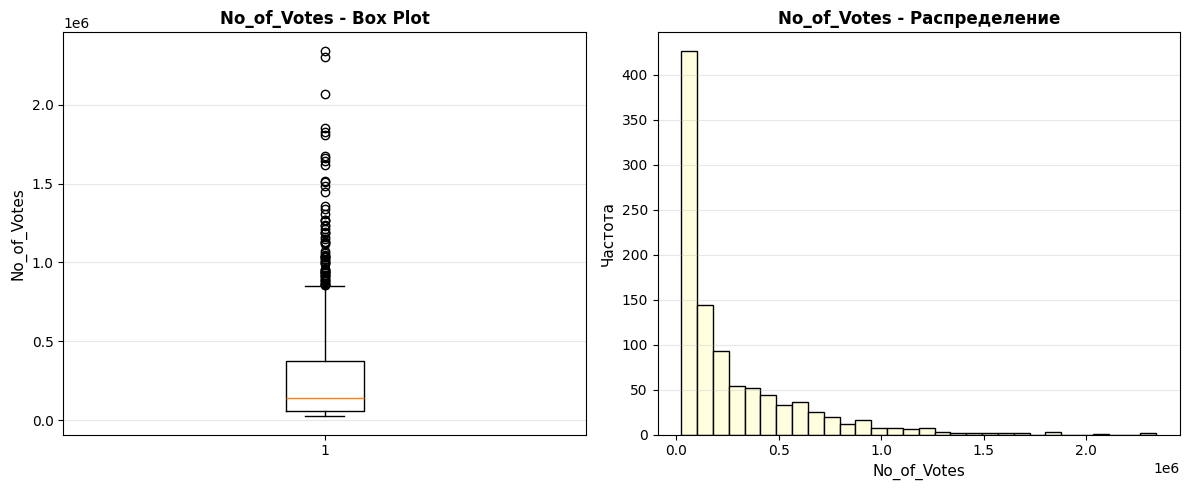


Q1 (25%): 55526.25
Q3 (75%): 374161.25
IQR: 318635.00
Нижний предел: -422426.25
Верхний предел: 852113.75
Выбросов: 67 (6.7%)
Min: 25088.00, Max: 2343110.00
Среднее: 273692.91, Медиана: 138548.50


In [ ]:
# No_of_Votes
print("\nNO_OF_VOTES - ВЫЯВЛЕНИЕ АНОМАЛИЙ")

print(f"\nВсего значений: {df_full['No_of_Votes'].notna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df_full['No_of_Votes'].dropna(), vert=True)
axes[0].set_ylabel('No_of_Votes', fontsize=11)
axes[0].set_title('No_of_Votes - Box Plot', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(df_full['No_of_Votes'].dropna(), bins=30, color='lightyellow', edgecolor='black')
axes[1].set_xlabel('No_of_Votes', fontsize=11)
axes[1].set_ylabel('Частота', fontsize=11)
axes[1].set_title('No_of_Votes - Распределение', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Q1 = df_full['No_of_Votes'].quantile(0.25)
Q3 = df_full['No_of_Votes'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_full[(df_full['No_of_Votes'] < lower_bound) | (df_full['No_of_Votes'] > upper_bound)]['No_of_Votes']

print(f"\nQ1 (25%): {Q1:.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижний предел: {lower_bound:.2f}")
print(f"Верхний предел: {upper_bound:.2f}")
print(f"Выбросов: {len(outliers)} ({len(outliers)/len(df_full)*100:.1f}%)")
print(f"Min: {df_full['No_of_Votes'].min():.2f}, Max: {df_full['No_of_Votes'].max():.2f}")
print(f"Среднее: {df_full['No_of_Votes'].mean():.2f}, Медиана: {df_full['No_of_Votes'].median():.2f}")


# 5.	Визуализация с помощью matplotlib
Должны быть построены как минимум:

*	Гистограмма (для распределения числового признака),
*	Столбчатая диаграмма (для распределения категориального признака),
*	Диаграмма рассеяния (scatter plot) с использованием пузырьков (размер точки должен кодировать третий признак — числовой или категориальный),
*	Box plot для оценки выбросов,
*	Любая дополнительная визуализация по усмотрению (например, pie chart, line plot и т.д.).
*	Все графики должны быть построены исключительно с помощью matplotlib (без seaborn, plotly, pandas.plot и т.п.).


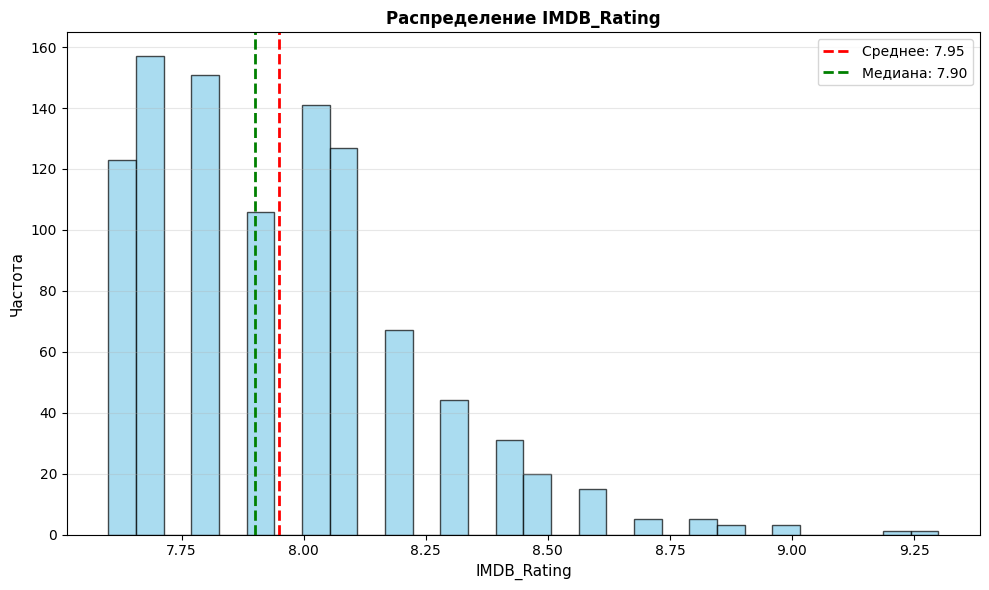

In [ ]:
# 1. Гистограмма IMDB_Rating

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(df_full['IMDB_Rating'].dropna(), bins=30, color='skyblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('IMDB_Rating', fontsize=11)
ax.set_ylabel('Частота', fontsize=11)
ax.set_title('Распределение IMDB_Rating', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.axvline(df_full['IMDB_Rating'].mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {df_full["IMDB_Rating"].mean():.2f}')
ax.axvline(df_full['IMDB_Rating'].median(), color='green', linestyle='--', linewidth=2, label=f'Медиана: {df_full["IMDB_Rating"].median():.2f}')
ax.legend()

plt.tight_layout()
plt.show()


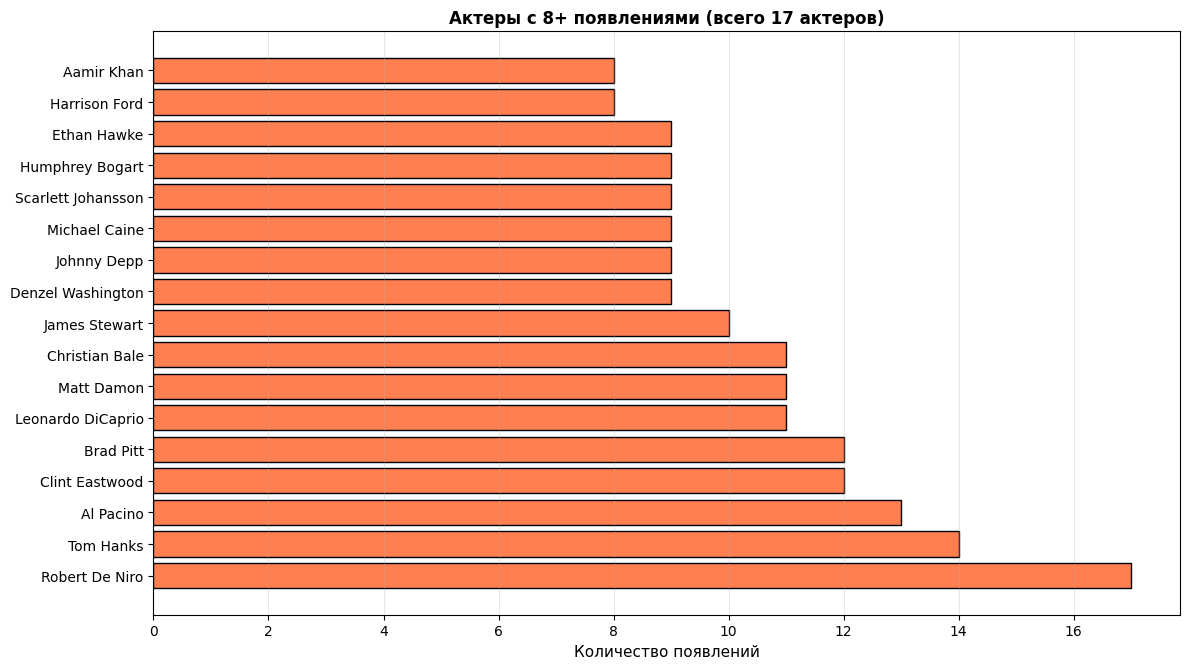

Всего актеров с 8+ появлениями: 17


In [ ]:
# 2. Столбчатая диаграмма - Актеры с 8+ появлениями

# Объединяем всех актеров из всех 4 столбцов
all_actors = pd.concat([df_full['Star1'], df_full['Star2'], df_full['Star3'], df_full['Star4']], ignore_index=True)

# Считаем появления
actor_counts = all_actors.value_counts()

# Берем только тех, кто встречается 8+ раз
actors_8plus = actor_counts[actor_counts >= 8].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, len(actors_8plus)*0.4))

ax.barh(range(len(actors_8plus)), actors_8plus.values, color='coral', edgecolor='black')
ax.set_yticks(range(len(actors_8plus)))
ax.set_yticklabels(actors_8plus.index, fontsize=10)
ax.set_xlabel('Количество появлений', fontsize=11)
ax.set_title(f'Актеры с 8+ появлениями (всего {len(actors_8plus)} актеров)', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Всего актеров с 8+ появлениями: {len(actors_8plus)}")


Корреляция между годом и рейтингом: -0.131


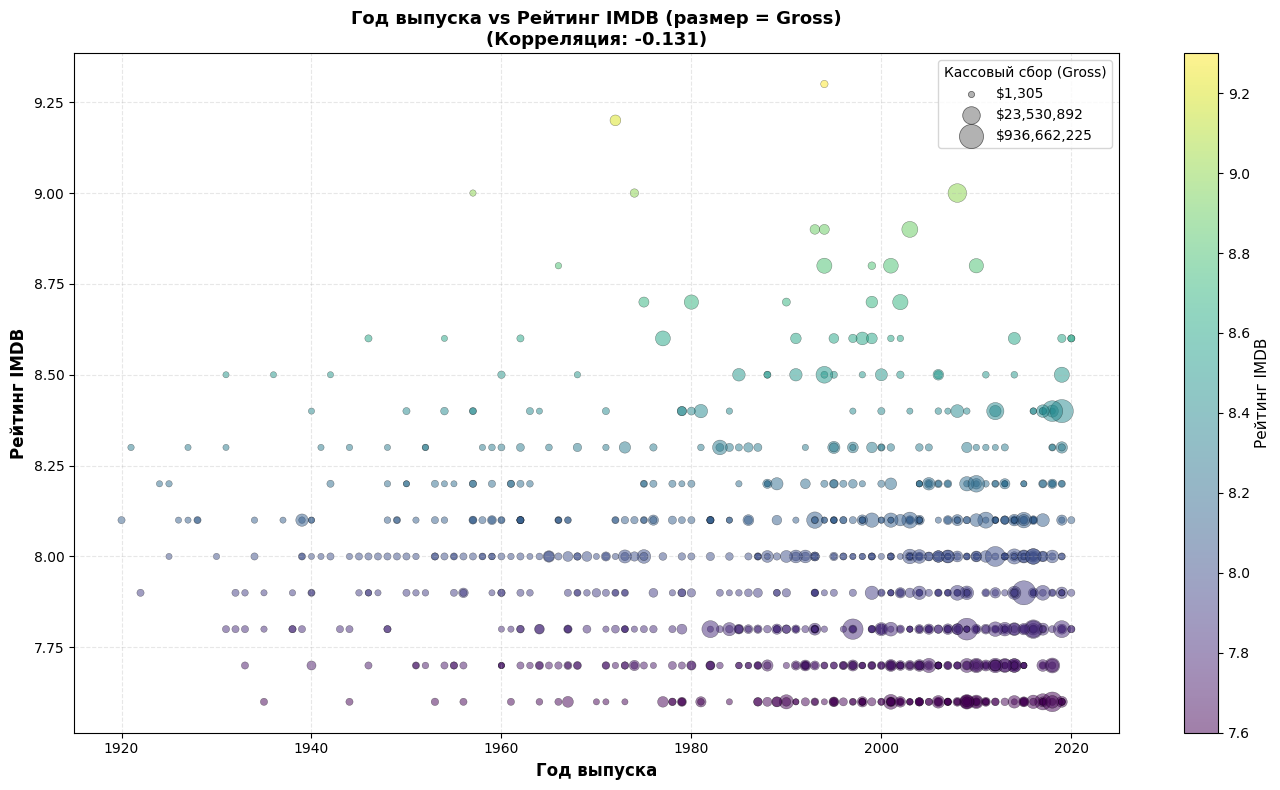

In [ ]:
# 3. Год выпуска vs Рейтинг IMDB, размер пузырьков зависит от Gross

df_full['Released_Year'] = pd.to_numeric(df_full['Released_Year'], errors='coerce')

# Вычисляем корреляцию
correlation = df_full['Released_Year'].corr(df_full['IMDB_Rating'])
print(f"Корреляция между годом и рейтингом: {correlation:.3f}")

# Масштабируем размер пузырьков (от 20 до 300)
size_normalized = (df_full['Gross'] - df_full['Gross'].min()) / \
                  (df_full['Gross'].max() - df_full['Gross'].min()) * 280 + 20

# Создаем график
fig, ax = plt.subplots(figsize=(14, 8))

scatter = ax.scatter(df_full['Released_Year'],
                     df_full['IMDB_Rating'],
                     s=size_normalized,
                     alpha=0.5,
                     c=df_full['IMDB_Rating'],
                     cmap='viridis',
                     edgecolors='black',
                     linewidth=0.3)

ax.set_xlabel('Год выпуска', fontsize=12, fontweight='bold')
ax.set_ylabel('Рейтинг IMDB', fontsize=12, fontweight='bold')
ax.set_title(f'Год выпуска vs Рейтинг IMDB (размер = Gross)\n(Корреляция: {correlation:.3f})',
             fontsize=13, fontweight='bold')
ax.grid(alpha=0.3, linestyle='--')

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Рейтинг IMDB', fontsize=11)

# Легенда для размеров
legend_sizes = [20, 160, 300]
legend_labels = [f'${df_full["Gross"].min():,.0f}', f'${df_full["Gross"].median():,.0f}', f'${df_full["Gross"].max():,.0f}']
legend_points = [ax.scatter([], [], s=s, c='gray', alpha=0.6, edgecolors='black', linewidth=0.5)
                 for s in legend_sizes]
ax.legend(legend_points, legend_labels, title='Кассовый сбор (Gross)',
         loc='best', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()


Q1 (25%): 7.70
Q3 (75%): 8.10
IQR: 0.40
Нижний предел: 7.10
Верхний предел: 8.70
Выбросов: 13 (1.3%)
Min: 7.60, Max: 9.30
Среднее: 7.95, Медиана: 7.90


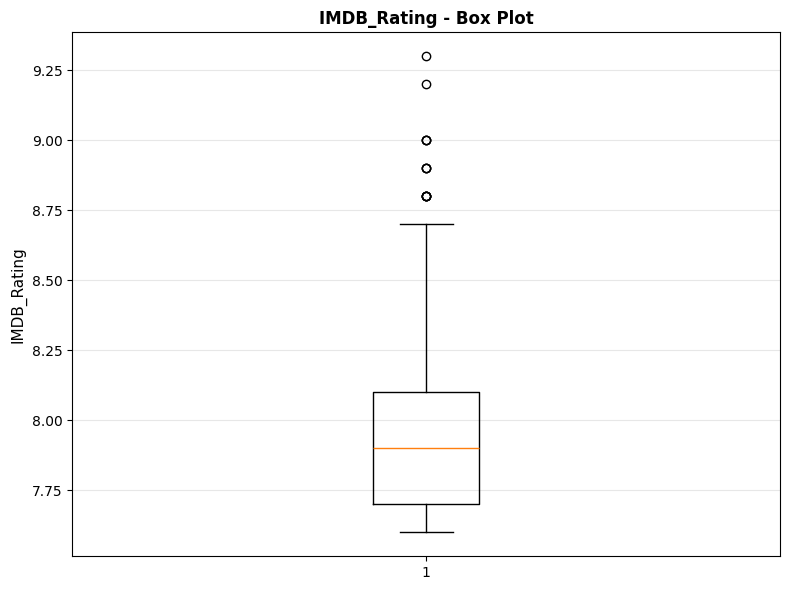

In [ ]:
# 4. Box plot для IMDB-rating

fig, ax = plt.subplots(figsize=(8, 6))

ax.boxplot(df_full['IMDB_Rating'].dropna(), vert=True)
ax.set_ylabel('IMDB_Rating', fontsize=11)
ax.set_title('IMDB_Rating - Box Plot', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Статистика выбросов
Q1 = df_full['IMDB_Rating'].quantile(0.25)
Q3 = df_full['IMDB_Rating'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_full[(df_full['IMDB_Rating'] < lower_bound) | (df_full['IMDB_Rating'] > upper_bound)]['IMDB_Rating']

print(f"\nQ1 (25%): {Q1:.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижний предел: {lower_bound:.2f}")
print(f"Верхний предел: {upper_bound:.2f}")
print(f"Выбросов: {len(outliers)} ({len(outliers)/len(df_full)*100:.1f}%)")
print(f"Min: {df_full['IMDB_Rating'].min():.2f}, Max: {df_full['IMDB_Rating'].max():.2f}")
print(f"Среднее: {df_full['IMDB_Rating'].mean():.2f}, Медиана: {df_full['IMDB_Rating'].median():.2f}")

plt.tight_layout()
plt.show()

Минимальный год в данных: 1920
Максимальный год в данных: 2020


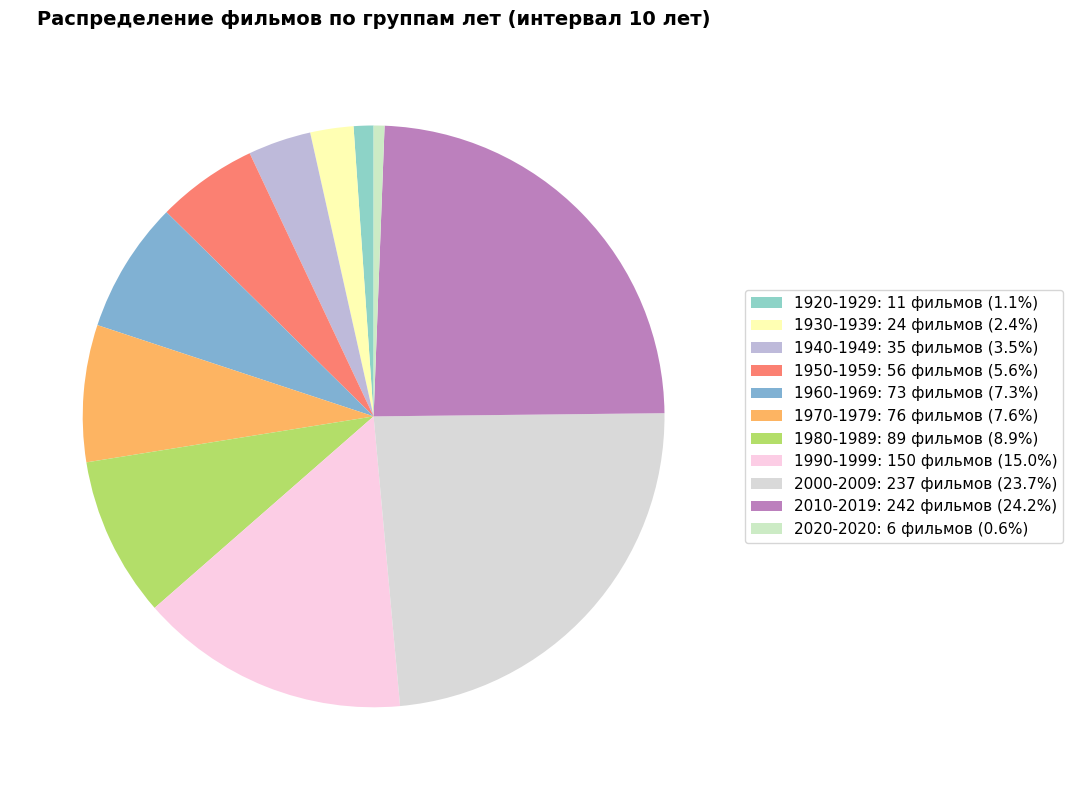

In [ ]:
# 5. Pie chart - Распределение фильмов по группам лет (интервал 10 лет)

# Берем реальный минимальный и максимальный годы из таблицы
min_year = int(df_full['Released_Year'].min())
max_year = int(df_full['Released_Year'].max())

print(f"Минимальный год в данных: {min_year}")
print(f"Максимальный год в данных: {max_year}")

# Создаем группы по 10 лет, начиная с минимального года
bins = list(range(min_year, max_year + 1, 10))
if bins[-1] != max_year + 1:
    bins.append(max_year + 1)


labels = [f'{bins[i]}-{bins[i+1]-1}' for i in range(len(bins)-1)]

df_full['Year_Group'] = pd.cut(df_full['Released_Year'], bins=bins, labels=labels, right=False)

# Подсчитываем количество фильмов в каждой группе
year_counts = df_full['Year_Group'].value_counts().sort_index()


# Создаем pie chart
fig, ax = plt.subplots(figsize=(14, 8))

colors = plt.cm.Set3(range(len(year_counts)))

wedges, texts = ax.pie(year_counts.values,
                        startangle=90,
                        colors=colors)

ax.set_title('Распределение фильмов по группам лет (интервал 10 лет)',
             fontsize=14, fontweight='bold', pad=20)

# Легенда с количеством и процентами
legend_labels = []
for label, count in zip(year_counts.index, year_counts.values):
    pct = count / year_counts.sum() * 100
    legend_labels.append(f'{label}: {count} фильмов ({pct:.1f}%)')

ax.legend(legend_labels, loc='center left', bbox_to_anchor=(1, 0, 0.5, 1), fontsize=11, frameon=True)

plt.tight_layout()
plt.show()


Поскольку в базе данных присутствуют фильмы только до 2020, то в последнее десятилетие вошел один год (сам 2020)

## 1. Информативность признаков
Наиболее информативными являются следующие признаки:

IMDB_Rating — один из ключевых признаков. Медиана составляет 7.90, среднее 7.95, с диапазоном от 7.60 до 9.30. Распределение сконцентрировано в узком диапазоне 7.75-8.10, где находится 50% всех фильмов (IQR = 0.40). Это указывает на высокую однородность фильмов в топ-1000 — все они высокого качества.

No_of_Votes — демонстрирует высокую вариативность с экспоненциальным распределением. Q1 составляет 55,536 голосов, а максимум превышает 2.3 млн. Это делает признак информативным для выявления различий в популярности фильмов. Большинство фильмов (75%) получили менее 200,000 голосов, что указывает на концентрацию оценок в нижнем диапазоне.

Meta_score — показывает хорошую вариативность с диапазоном 30-100 и медианой 79.0. Q1 = 72.0, Q3 = 85.25, что дает IQR = 13.25. Распределение близко к нормальному с концентрацией в диапазоне 70-85, содержащем более 200 фильмов.

Runtime — также информативен с диапазоном от 50 до 313 минут, медиана 120 минут. Q1 = 103, Q3 = 137, IQR = 34 минуты. Распределение нормальное с максимумом около 110-120 минут, что соответствует стандартной длительности художественного фильма.

Released_Year — содержит информацию о временном тренде. Диапазон от 1920 до 2020 года показывает, что датасет охватывает столетие кинематографии, но сосредоточен на современных фильмах (48.3% из период 2000-2019).

## 2. Пропуски и аномалии данных
Явные пропуски:

Certificate — 101 пропуск (10.1%). После заполнения видна концентрация на рейтингах U (220 фильмов), A (210), и R (148). Это указывает на то, что датасет включает фильмы с различными возрастными рейтингами, но с акцентом на семейные (U) и взрослые (A) фильмы.

Meta_score — 157 пропусков (15.7%). Это довольно значительный уровень пропусков, что может быть связано с отсутствием критических оценок для некоторых фильмов. После заполнения распределение остается репрезентативным.

Gross — 169 пропусков (16.9%), заполнены медианой $23,530,892. Это наибольший уровень пропусков среди ключевых числовых признаков, что объяснимо тем, что кассовые данные не всегда доступны, особенно для старых фильмов.

Все остальные признаки (Poster_Link, Series_Title, Released_Year, Runtime, Genre, IMDB_Rating, Overview, Director, Star1-4, No_of_Votes) — полные данные без пропусков.

Аномалии (выбросы):

No_of_Votes — содержит значительное количество выбросов (видно на box plot). Верхний предел IQR составляет ~400,000 голосов, но фильмы типа "The Shawshank Redemption" имеют более 2.3 млн голосов. Это естественно для датасета Top 1000, где популярные фильмы получают непропорционально больше оценок.

IMDB_Rating — выбросы минимальны (13 выбросов, 1.3%). Нижний предел = 7.10, верхний = 8.70. Фильмы с рейтингом выше 8.70 (максимум 9.30) считаются выбросами, но их всего 13 — это редкие шедевры высочайшего качества.

Meta_score — низкие значения (30-54) содержат множество выбросов при нормальном распределении. Это указывает на то, что в датасете есть фильмы, которые критики оценили значительно ниже среднего, но все еще вошли в Top 1000 IMDB благодаря высоким оценкам пользователей.

Runtime — содержит небольшое количество выбросов. Верхний предел = 188 минут, но есть фильмы длительностью до 313 минут (эпические фильмы типа "Gangs of Wasseypur" или исторических драм). Нижний выброс при 50 минутах — вероятно, это телефильмы или короткие форматы.


## 3. Гипотезы на основе визуализаций
Гипотеза 1: Слабая обратная связь между возрастом фильма и его рейтингом

Корреляция между Released_Year и IMDB_Rating составляет -0.131, что указывает на слабую отрицательную связь. Это означает, что старые фильмы в Top 1000 имеют немного более высокие рейтинги, чем новые. Объяснение: в Top 1000 попадают только лучшие старые фильмы, тогда как новые фильмы включаются более демократично.

Гипотеза 2: Кассовые сборы не коррелируют с качеством

Scatter plot "Год выпуска vs IMDB Rating" с размером пузырьков, соответствующих Gross, показывает, что размер пузырьков не имеет четкой связи с вертикальным положением (рейтингом). Фильмы с низким кассовым сбором могут иметь высокие рейтинги, и наоборот. Это указывает на то, что финансовый успех и критическое признание — независимые факторы.

Гипотеза 3: Meta_score и IMDB_Rating сильно коррелируют

На графике "Meta_score ДО и ПОСЛЕ обработки" видно, что распределение остается стабильным и близким к нормальному. Это означает, что критические оценки (Meta_score) и пользовательские рейтинги (IMDB_Rating) обычно совпадают в своих оценках качества. Медиана Meta_score (79) соответствует высокому качеству, так же как медиана IMDB_Rating (7.90).

Гипотеза 4: Популярность фильма имеет экспоненциальное распределение

No_of_Votes показывает классическое экспоненциальное распределение: большинство фильмов получают 50,000-200,000 голосов, а небольшой процент (топ-фильмы) получают в 10+ раз больше голосов. Это естественно для сетей оценок, где популярные фильмы получают диспропорционально больше внимания.

Гипотеза 5: Актеры высокой квалификации регулярно появляются в Top 1000

17 актеров имеют 8+ появлений в Top 1000. Robert De Niro лидирует с 16 появлениями, Tom Hanks — 14. Это указывает на то, что определенные актеры постоянно выбираются для ролей высокого качества или имеют таланты, позволяющие им участвовать в лучших проектах.
